# 02 · Ethical audit of a recommender
**Session B, 150 minutes including a break.** Guided practical: approximately 40 minutes after the case walkthroughs. Slides 41–80 match this notebook.

Six cases: (1) discovery/popularity, (2) provider opportunity, (3) user quality, (4) privacy, (5) feedback loops, (6) engagement and agency. One common procedure connects them: **stakeholder → mechanism → evidence → response → recheck**.

**Part 1** contains guided measurements and simulations. **Part 2** contains project TODOs. Real benchmark measurements are labeled separately from synthetic cases; the policy case is a document-based analysis, not a reconstruction from private platform data.

## Part 1 — Guided audit
### 1. Evidence and boundaries
The same MovieLens 100K data card, license and chronological protocol apply as in Notebook 01. Read that notebook first. Raw/individual processed records are generated locally and omitted from the teaching ZIP because the source license restricts redistribution.

A metric difference is an observation. A harm hypothesis needs an affected person and a mechanism. A causal or legal conclusion needs stronger evidence than an offline movie benchmark. Never infer gender, ethnicity or disability from names, clothing or images to fill an audit table.

In [1]:
from pathlib import Path  # Resolve the practical folder.
import sys, json  # Import paths and JSON support.
import numpy as np  # Use arrays for calculations.
import pandas as pd  # Use labeled tables.
import matplotlib.pyplot as plt  # Create diagnostic figures.
from IPython.display import display  # Show notebook tables.
from threadpoolctl import threadpool_limits  # Keep laptop computations predictable.
ROOT = Path.cwd()  # Start from the current directory.
if not (ROOT / 'src').is_dir():  # Support launching from notebooks/.
    ROOT = ROOT.parent  # Move to the project root.
assert (ROOT / 'src/recsys_lab.py').exists(), 'Open from the practical root or notebooks folder.'  # Check location.
sys.path.insert(0, str(ROOT / 'src'))  # Make the teaching module importable.
from download_data import download  # Import the local downloader.
from recsys_lab import *  # Import the documented teaching functions.
plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 12})  # Set readable plots.

In [2]:
download(ROOT)  # Obtain the source locally if needed.
ratings, movies, splits = prepare(ROOT)  # Recreate verified processed data.
fit_data = pd.concat([splits['train'], splits['validation']], ignore_index=True)  # Use the frozen first 90%.
test_data = splits['test']  # Keep the final 10% for evaluation.
cache = ROOT / 'data/processed/ItemKNN_cache.npz'  # Locate the optional local cache.
if cache.exists():  # Reuse a model created with this supplied protocol.
    stored = np.load(cache)  # Read local arrays.
    model = ItemKNN()  # Create the model container.
    model.pred, model.rank_scores, model.R = stored['pred'], stored['rank_scores'], stored['R']  # Restore scores and fitted observations.
    model.mask = model.R != 0  # Recover the observation mask.
    assert np.array_equal(model.R, matrix(fit_data)), 'Stale cache: rerun Notebook 01.'  # Detect mismatched data.
else:  # Allow this notebook to run independently after source download.
    with threadpool_limits(limits=1):  # Limit unnecessary BLAS threads.
        model = ItemKNN().fit(fit_data)  # Fit the declared reference model.
summary, per_user, rec = evaluate(model, test_data)  # Establish the baseline quality.
print('Ranking users:', summary['evaluated_users'], 'of', summary['test_users'], 'test users')  # Expose the denominator.

Source files available: /workspace/scratch/a78d3bf087d5/build/recsys-lecture/practical/data/raw/movielens-100k
Ranking users: 153 of 166 test users


### 2. Case 1 — Discovery and popularity
**Stakeholders:** learners/consumers and less-visible creators. **Mechanism:** prior visibility creates interaction counts, which influence later recommendations. **Possible lost benefit:** useful alternatives remain undiscovered. Counts may also reflect demand, availability or quality; concentration alone does not prove unfairness.

Define the **head** as the top 20% of fitted-catalog items by fitted rating count, rounding the item count upward. The remainder is the long tail. These activity groups are **not provider-size or merit labels**.

[Singh & Joachims (2018)](https://arxiv.org/abs/1802.07281) provides a ranking-exposure framework. Our particular position discount and operational head/tail split are teaching choices.

Eligible movies: 1637 Head movies: 328
Share of fitted ratings in head: 0.6427222222222222


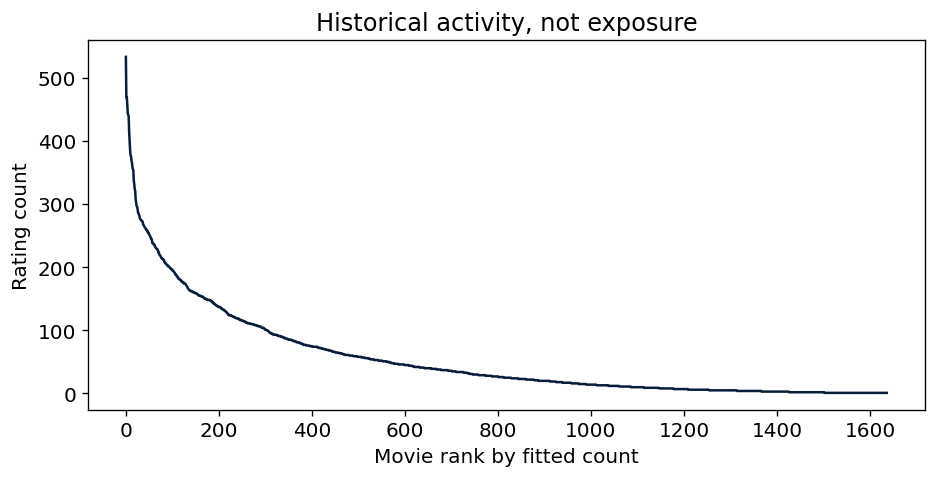

In [3]:
counts = model.mask.sum(axis=0)  # Count fitted ratings for each item ID.
eligible = model.mask.any(axis=0)  # Identify the fitted catalog.
head_size = int(np.ceil(eligible.sum() * .2))  # Define the top fifth of that catalog.
head = np.argsort(-counts, kind='stable')[:head_size]  # Use deterministic tie-breaking.
print('Eligible movies:', eligible.sum(), 'Head movies:', head_size)  # Report the actual groups.
print('Share of fitted ratings in head:', counts[head].sum() / counts.sum())  # Quantify observed concentration.
fig, ax = plt.subplots()  # Create an activity figure.
ax.plot(np.sort(counts[eligible])[::-1], color='#041E3C')  # Plot fitted-period counts.
ax.set(xlabel='Movie rank by fitted count', ylabel='Rating count', title='Historical activity, not exposure')  # Prevent a false interpretation.
plt.show()  # Display the figure.

### 3. Compute modeled exposure and discovery metrics
Assume attention at rank r is `1/log2(r+1)`. A tail item at rank 2 of a three-item list receives `.631/(1+.631+.5)=29.6%` of that list’s modeled attention. This is **not actual impression or gaze data**.

- Catalog coverage = number of distinct recommended items / fitted catalog size.
- Tail share = tail position-weight / total position-weight.
- Novelty = average `−log2((count(i)+1)/(N+M))`; N=fitted ratings, M=all metadata items.
- Genre diversity = average pairwise `1−cosine` of genre indicators.

Each metric is a proxy. None establishes learning, cultural value, welfare or fairness by itself. Audit recommendations for the **same evaluated users** as quality, not for all 943 IDs indiscriminately.

In [4]:
weights = 1 / np.log2(np.array([2, 3, 4]))  # Define the three position weights.
print('Synthetic rank-2 share:', weights[1] / weights.sum())  # Reproduce 29.6%.
audit_users = per_user.user_id.to_numpy()  # Keep the same evaluation population.
before = audit(rec, model, movies, audit_users)  # Measure the reference lists.
display(pd.Series(before, name='ItemKNN'))  # Display all discovery measures.

Synthetic rank-2 share: 0.2960819109658652


catalog_coverage             0.162492
long_tail_exposure_share     0.642897
mean_genre_diversity         0.668424
mean_novelty_bits           11.506040
Name: ItemKNN, dtype: float64

### 4. Respond with MMR, then recheck
MMR selects the next item by `λ×relevance − (1−λ)×max_similarity_to_selected`. This notebook adapts [Carbonell & Goldstein (1998)](https://doi.org/10.1145/290941.291025) to recommendations.

Toy after item A: B has relevance .88 and similarity .95; C has relevance .80 and similarity .20. At λ=.7, B=.331 and C=.500, so choose C. All values must be on comparable scales.

Real experiment: ItemKNN generates 50 unseen eligible candidates; normalize their relevance scores to [0,1] **within each pool**; use genre cosine; choose top 10 with λ=.75. These are predeclared settings, not a search over test performance. MMR does not guarantee provider fairness, long-tail promotion or safety.

In [5]:
print('Toy B:', .7*.88 - .3*.95, 'Toy C:', .7*.80 - .3*.20)  # Verify the hand calculation.
reranked = mmr(model, movies, k=10, pool=50, lam=.75)  # Re-rank using the declared intervention.
after_summary, after_per_user, _ = evaluate(model, test_data, recommendations=reranked)  # Recheck held-out quality.
after = audit(reranked, model, movies, audit_users)  # Use the identical user population.
comparison = pd.DataFrame({'ItemKNN': {**before, 'NDCG@10': summary['NDCG@10']}, 'MMR': {**after, 'NDCG@10': after_summary['NDCG@10']}})  # Combine benefit and cost.
display(comparison.round(6))  # Do not hide an unfavorable direction.

Toy B: 0.331 Toy C: 0.49999999999999994


,ItemKNN,MMR
catalog_coverage,0.162492,0.167379
long_tail_exposure_share,0.642897,0.653265
mean_genre_diversity,0.668424,0.828914
mean_novelty_bits,11.506040,11.539384
NDCG@10,0.061070,0.061893


Mean NDCG change: 0.0008235219326762927 95% bootstrap interval: (-0.008131393092629217, 0.010208234553292991)


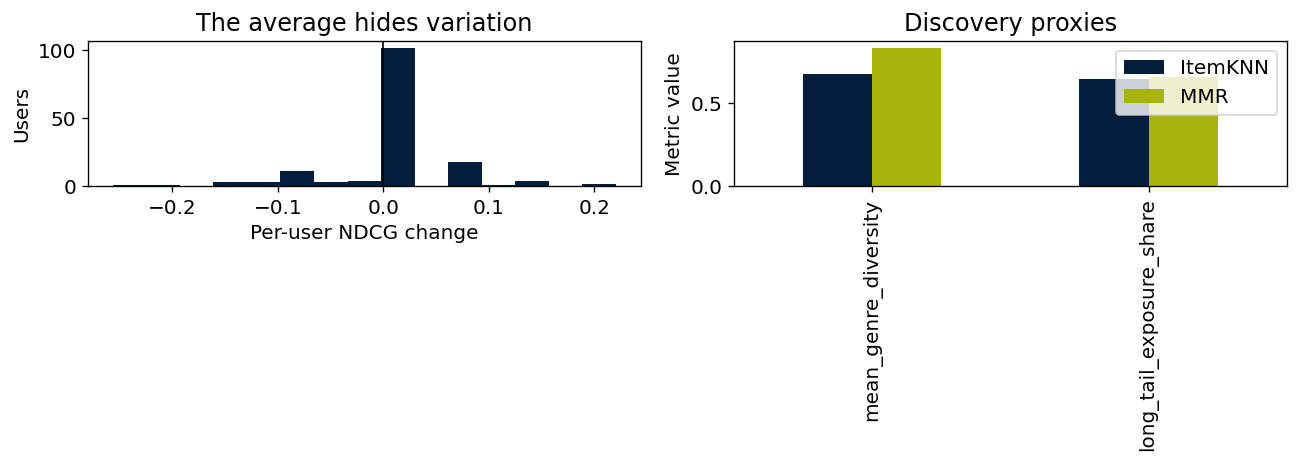

In [6]:
paired = after_per_user[['user_id', 'ndcg']].merge(per_user[['user_id', 'ndcg']], on='user_id', suffixes=('_mmr', '_base'))  # Align the same users.
changes = paired.ndcg_mmr - paired.ndcg_base  # Keep pairing in the quality comparison.
mean, low, high = bootstrap_mean(changes)  # Resample user-level differences 1,000 times.
print('Mean NDCG change:', mean, '95% bootstrap interval:', (low, high))  # Report uncertainty.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))  # Show a relevance distribution and a discovery comparison.
axes[0].hist(changes, bins=15, color='#041E3C')  # Inspect who gains or loses ranking quality.
axes[0].axvline(0, color='black', linewidth=1)  # Mark no change.
axes[0].set(xlabel='Per-user NDCG change', ylabel='Users', title='The average hides variation')  # Label the tradeoff.
comparison.loc[['mean_genre_diversity', 'long_tail_exposure_share']].plot.bar(ax=axes[1], color=['#041E3C', '#A9B40A'])  # Compare two bounded metrics.
axes[1].set(title='Discovery proxies', ylabel='Metric value')  # Do not call these welfare scores.
plt.tight_layout()  # Keep labels readable.
plt.show()  # Display the audit figure.

**Interpretation task:** report the actual direction and magnitude of each change. Does the evidence support the intervention’s stated aim? The fixed-sample bootstrap does not cover all uncertainty in model selection, dataset choice or future behavior. Predefine an acceptable relevance cost with stakeholders; a post-hoc tolerance is exploratory.

**Response options:** offer a user-selected discovery mode, change the candidate-support rule, improve metadata, or reject MMR if its costs outweigh the supported benefit. A diversity increase is not automatically an ethical improvement.

### 5. Case 2 — Provider opportunity (synthetic)
A–C come from established providers; D–F from smaller providers. Scores and relevance grades are stipulated. MovieLens has no such provider labels, so this is a separate six-row case, not a disguised MovieLens result.

Baseline `[A,B,C]` gives small providers zero top-three modeled exposure. An illustrative constraint “one small provider in the top two” gives `[A,D,B]`: small share 29.6%. Is that justified? A balanced catalog alone does not entitle each group to 50% attention. Consider comparable merit, entry barriers, user needs and the platform’s commitments.

In [7]:
providers = pd.read_csv(ROOT / 'data/raw/synthetic/provider_items.csv').set_index('item')  # Load all stated assumptions.
display(providers)  # Inspect score and relevance as different columns.
def provider_result(order):  # Evaluate one explicit three-item list.
    chosen = providers.loc[order]  # Preserve the given order.
    small = chosen.provider_group.eq('Small').to_numpy()  # Find the group positions.
    gain = 2.0**chosen.relevance_grade.to_numpy() - 1  # Use graded gain rather than binary relevance.
    return float(small @ weights / weights.sum()), float(gain @ weights)  # Return exposure share and DCG.
base_share, ideal_dcg = provider_result(['A', 'B', 'C'])  # Establish the ideal graded baseline.
new_share, new_dcg = provider_result(['A', 'D', 'B'])  # Evaluate the constrained order.
display(pd.DataFrame({'order':['A B C','A D B'], 'small_share':[base_share,new_share], 'DCG':[ideal_dcg,new_dcg], 'NDCG':[1,new_dcg/ideal_dcg]}))  # Show both benefit and cost.

,provider_group,score,relevance_grade
item,,,
A,Established,0.95,3
B,Established,0.92,3
C,Established,0.90,2
D,Small,0.87,2
E,Small,0.83,1
F,Small,0.75,1


,order,small_share,DCG,NDCG
0,A B C,0.000000,12.916508,1.000000
1,A D B,0.296082,12.392789,0.959454


**Identify → respond → recheck:** specify whether the standard is equal opportunity, exposure proportional to defensible merit, or another contextual principle. Compare per-list with longer-run constraints. Recheck relevance, user-quality floors, provider exposure across requests and uncertainty in grades. A numeric parity target must have a reason beyond being easy to calculate.

### 6. Case 3 — Unequal service quality
A fictional four-user example has NDCG `[.2,.4]` for low-history users and `[.9,.9]` for high-history users: means .3 versus .9, overall .6. This shows why averages can hide differences; it does **not** predetermine what the real data must show.

In the real audit, use fitted-history counts: cold=0; low=positive count up to Q1; middle=(Q1,Q3]; high=>Q3. These operational slices are not ethnicity, gender, income, disability or ability. Compare counts and uncertainty. Different truth-set sizes, user populations and fallback behavior can affect the result.

In [8]:
history = model.mask.sum(axis=1)  # Measure history using only fitted events.
q1, q3 = np.quantile(history[history > 0], [.25, .75])  # Define cutpoints without test quality.
print('History cutpoints Q1, Q3:', q1, q3)  # Make the slice definition reproducible.
slice_rows = []  # Collect aggregate slice results.
for name, mask in [('cold', history==0), ('low_history', (history>0)&(history<=q1)), ('middle', (history>q1)&(history<=q3)), ('high_history', history>q3)]:  # Define disjoint slices.
    values = per_user.loc[per_user.user_id.isin(np.flatnonzero(mask)+1), 'ndcg']  # Restrict to evaluated users.
    if len(values):  # Avoid undefined means for empty slices.
        mean, lo, hi = bootstrap_mean(values)  # Estimate conditional user variability.
        slice_rows.append({'slice': name, 'n': len(values), 'mean_ndcg': mean, 'ci_low': lo, 'ci_high': hi})  # Preserve count and interval.
slice_table = pd.DataFrame(slice_rows)  # Create the audit table.
display(slice_table)  # Read what the evidence actually supports.

History cutpoints Q1, Q3: 33.0 147.0


,slice,n,mean_ndcg,ci_low,ci_high
0,cold,76,0.118563,0.088988,0.153200
1,low_history,10,0.007336,0.000000,0.022009
2,middle,32,0.000000,0.000000,0.000000
3,high_history,35,0.007415,0.000000,0.016586


**Important result:** in this supplied run the cold slice performs better than warm slices, and the middle slice has no top-10 hits. Do not claim the benchmark confirms a cold-user disadvantage. Inspect CF support and the rating-loss/ranking mismatch; the cold fallback has a different deterministic order. This is not evidence that reducing history improves quality causally.

**Possible responses to test:** explicit goal onboarding, item-content features, robust priors, a candidate-support rule, and a useful non-personalized option. Recheck sparse-user quality and burden; do not collect unlimited personal information as a shortcut.

### 7. Case 4 — Privacy and linkage (synthetic)
Historical reference: [Narayanan & Shmatikov (2008)](https://systems.cs.columbia.edu/private-systems-class/papers/Narayanan2008Robust.pdf) demonstrated linkage risks in the Netflix Prize data. Removing names did not automatically anonymize rich rating histories.

Our safe toy has three pseudonyms and two rare-film ratings. An external clue X=5 matches P17 and P28; a second clue Y=1 leaves P17. This exact intersection is a simplified mechanism, not the paper’s complete robust method.

**Do not attempt to reidentify real users, collect external profiles, or publish linked records.** The exercise only uses fictional rows.

In [9]:
privacy = pd.read_csv(ROOT / 'data/raw/synthetic/privacy_toy.csv')  # Load fictional rating histories.
display(privacy)  # Show the full safe toy.
first = privacy.query('rare_film_X_rating == 5')  # Apply one public clue.
second = first.query('rare_film_Y_rating == 1')  # Intersect with the second clue.
print('After one clue:', first.pseudonym.tolist())  # Two records remain.
print('After both clues:', second.pseudonym.tolist())  # Only P17 remains.

After one clue: ['P17', 'P28']
After both clues: ['P17']


,pseudonym,rare_film_X_rating,rare_film_Y_rating
0,P17,5,1
1,P28,5,4
2,P39,1,1


**Identify:** specify the attacker, auxiliary information, released fields and sensitive consequence. **Respond:** minimize data/retention; use controlled access and aggregation; evaluate a defined privacy mechanism when appropriate. Hashing IDs alone leaves linkage patterns. Federated computation can still leak through updates; differential privacy needs a stated adjacency relation, privacy budget and implementation.

**Recheck:** privacy risk and utility jointly, including small aggregate cells and downstream access. MovieLens’s public availability does not make identifying its users an appropriate class activity.

### 8. Case 5 — Feedback and algorithmic confounding (synthetic)
[Chaney, Stewart & Engelhardt (2018)](https://arxiv.org/abs/1710.11214) studies recommendation-induced feedback in simulations. Do not describe every real platform as causally proven to behave the same way.

Toy assumptions: head/tail initial counts `[8,2]`; 20 impressions per round; equal true click probability .5; clicks are expected values. Exploitation allocates proportionally to counts; exploration mixes 80% proportional allocation with 20% uniform allocation. Update counts with generated clicks.

First-round tail exposure: 4.0 with exploitation, 5.2 with exploration. Pure proportional exploitation **preserves** the initial 80/20 share in this toy; it does not necessarily amplify it. Unequal observed clicks can persist despite equal appeal.

,policy,round,head_exposure,tail_exposure,head_clicks,tail_clicks
0,exploit,0,16.000000,4.000000,8.000000,2.000000
1,exploit,1,16.000000,4.000000,8.000000,2.000000
2,exploit,2,16.000000,4.000000,8.000000,2.000000
3,exploit,3,16.000000,4.000000,8.000000,2.000000
4,exploit,4,16.000000,4.000000,8.000000,2.000000
5,explore_20pct,0,14.800000,5.200000,7.400000,2.600000
6,explore_20pct,1,14.320000,5.680000,7.160000,2.840000
7,explore_20pct,2,14.032000,5.968000,7.016000,2.984000
8,explore_20pct,3,13.830400,6.169600,6.915200,3.084800
9,explore_20pct,4,13.677184,6.322816,6.838592,3.161408


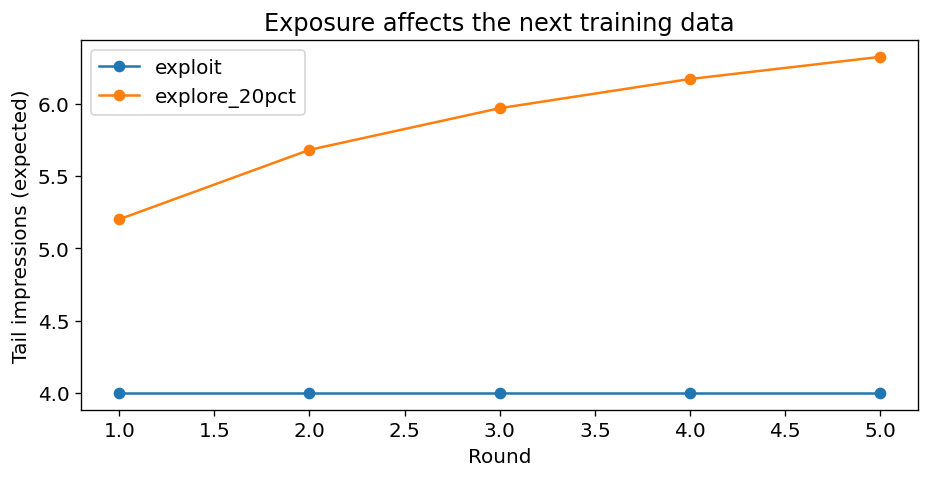

In [10]:
simulation = feedback_simulation()  # Run the stated recurrence, not a fitted behavior model.
display(simulation)  # Inspect every round and assumption-dependent outcome.
fig, ax = plt.subplots()  # Compare allocation trajectories.
for policy, frame in simulation.groupby('policy'):  # Plot one line per policy.
    ax.plot(frame['round']+1, frame.tail_exposure, marker='o', label=policy)  # Track tail exposure.
ax.set(xlabel='Round', ylabel='Tail impressions (expected)', title='Exposure affects the next training data')  # State the quantity.
ax.legend()  # Identify the two policies.
plt.show()  # Display the simulation.

**Response and tradeoff:** exploration may create evidence about less-seen items, but needs eligibility, suitability and safety constraints. In real systems, log display probabilities and assess longer-term effects. Offline replay does not observe how people would react to another feed. A class project should simulate or design a study; it should not run an unapproved experiment on people.

### 9. Case 6 — Engagement, safety and agency (document-based)
On **6 February 2026**, the European Commission announced **preliminary** findings concerning TikTok’s addictive design, including a highly personalized recommender alongside infinite scrolling and other interface features. This is a dated regulator assessment, not a final judicial ruling or a MovieLens finding. [Primary Commission release](https://digital-strategy.ec.europa.eu/en/news/commission-preliminarily-finds-tiktoks-addictive-design-breach-digital-services-act).

The Commission’s [14 July 2025 minors guidance](https://digital-strategy.ec.europa.eu/en/library/commission-publishes-guidelines-protection-minors) recommends safer recommendation pathways, more deliberate user signals and effective feed control. Distinguish guidance from binding legislation.

The [DSA primary text](https://eur-lex.europa.eu/legal-content/EN/TXT/?uri=CELEX%3A32022R2065) includes Article 27 parameter transparency and Article 38’s non-profiling option for VLOPs/VLOSEs. Scope and exemptions matter; do not apply Article 38 to every recommender indiscriminately.

**Audit design exercise (no private TikTok dataset is supplied):**
1. Identify a user whose intended stopping or learning goal might conflict with an engagement objective.
2. Specify evidence: repeated/night-time sessions, explicit goals, dismissals, content pathways, and user-reported control. One signal alone does not establish harm.
3. Propose a change: objective safeguards, stopping cues, user-chosen feed controls or safety constraints.
4. Explain how to measure effectiveness without unnecessary sensitive collection, and when to stop the study.

### 10. Complete a decision memo
Submit 400–600 words, one aggregate figure, one results table and the reproducible notebook. Use the following fields:

| Field | Your answer |
|---|---|
| Stakeholder and lost benefit | TODO |
| Recommendation stage and mechanism | TODO |
| Measured pattern vs interpretation | TODO |
| Intervention and alternative | TODO |
| Quality / opportunity / privacy tradeoff | TODO |
| Uncertainty and missing evidence | TODO |
| Keep, modify or reject; next recheck | TODO |

A valid conclusion may reject MMR or say the data cannot establish the proposed harm. Clear limits are part of a good audit.

## Part 2 — Final-project TODOs, hints and self-study
### Path A · Discovery or provider opportunity
**TODO 1:** justify an exposure principle with a stakeholder scenario. Do not infer provider identity from popularity.

**TODO 2:** compare MMR with at least one alternative, such as a long-tail quota, a calibrated topic mixture, or a longer-run provider allocation. Use validation to choose settings; test once. Record constraints and infeasible cases.

**TODO 3:** vary assumed attention weights (uniform, logarithmic, steeper discounts). Does the conclusion depend on your attention model? Inspect users who lose relevance, not only the average.

**Hint:** use the synthetic provider table to test formulas before applying any appropriately sourced provider dataset. A real extension needs provider labels, eligibility, a defensible merit measure and data-use permission.

In [11]:
def project_attention_weights(k, power=1.0):  # Parameterize a stated attention assumption.
    return 1 / np.log2(np.arange(2, k+2))**power  # Return steeper or shallower discounts.
# TODO: compare power values chosen in advance and report sensitivity.  # Keep relevance labels and users fixed.
# TODO: implement an alternative re-ranker with explicit eligibility and infeasibility handling.  # Explain the ethical principle.

### Path B · Quality and access for users
**TODO 1:** inspect the unexpected slice result rather than assuming a known direction. Compare distributions of available candidates, test positives, history counts, fallback rates and neighbor support.

**TODO 2:** implement a content-assisted or onboarding fallback; assess at least two alternatives. State what a meaningful service-quality floor would mean in your chosen context.

**TODO 3:** report paired quality changes and uncertainty. If appropriate labels for a protected-group audit are unavailable, state the gap; do not manufacture sensitive identities.

**Hint:** random splits and global time splits answer different questions. Compare them only with an explicit explanation; do not select the split that makes the model look best.

### Path C · Privacy and governance
**TODO 1:** extend the fictional linkage table with noisy or partial clues and calculate how candidate-set size changes.

**TODO 2:** evaluate an aggregate-release protection (minimum cell size or a clearly defined noise mechanism). State the threat, privacy claim, utility loss and limitations.

**TODO 3:** write a data-release and retention plan. Explain why hashed IDs, public availability or a small dataset do not remove ethical responsibilities.

**Hint:** do not claim differential privacy without specifying adjacency, sensitivity, noise distribution, budget and composition assumptions. No real-user reidentification is needed.

In [12]:
def project_link_candidates(frame, clues):  # Generalize exact matching on fictional records.
    keep = pd.Series(True, index=frame.index)  # Begin with every synthetic candidate.
    for field, value in clues.items():  # Process the explicitly supplied auxiliary clues.
        keep &= frame[field].eq(value)  # Intersect compatible rows.
    return frame.loc[keep].copy()  # Return a new fictional candidate table.
# TODO: evaluate partial/noisy clues using synthetic data only.  # Do not link real people.

### Path D · Feedback and agency
**TODO 1:** vary initial imbalance, true appeal, exploration fraction and response noise. Separate a persistent imbalance from amplification.

**TODO 2:** compare short-run relevance with long-run discovery and a simulated user goal. Explain assumptions that favor your chosen policy.

**TODO 3:** design a user-control audit: specify the control, what ranking behavior it should change, a fidelity test, and a comprehensibility test. An explanation must reflect the actual model mechanism.

**Optional causal extension:** simulate randomized logging with known propensities, then compare naive replay with inverse propensity weighting. Check overlap and weight variance. MovieLens does not supply these propensities; inventing them for the real data is invalid.

### Report rubric and reproducibility checklist
Use the same five-part rubric as Notebook 01. Include a predeclared protocol, a baseline, at least two plausible interventions, uncertainty, stakeholder consequences and a clear decision. Cite the primary papers and documents you actually use. Explain which experiments reproduce a published result and which are your own adaptation.

Keep restricted raw/individual data out of Git. Commit the downloader, source code, notebook, synthetic data, environment instructions, aggregate figures and a concise data card. State LLM assistance and be prepared to explain one function and recompute one result independently.